# AI Business Location Advisor
**Finding the Most Suitable Business Location in Baku City**


In [485]:
# Import the libraries used for data analysis, mapping, visualization and machine learning.
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import ipywidgets as widgets
import folium

## 1. Data haqqında ilk baxış

In [486]:
# Load the rent, metro, points-of-interest and district demographic datasets
rent = pd.read_csv("/content/baku_commercial_rent_realistic_synthetic (1).csv")
metro = pd.read_csv("/content/pathways.csv", sep=";", encoding="utf-8-sig")
poi = gpd.read_file("/content/azerbaijan.gpkg", layer="gis_osm_pois_free")
demo = pd.read_csv("/content/baku_district_demographics.csv")

In [487]:
# Merge district demographic information into the rent dataset and preview the added columns
rent = rent.merge(demo, on="district", how="left")
rent[["district", "pop", "dens", "youth"]].head()

,district,pop,dens,youth
0,Nəsimi,219.7,21970,40.3
1,Nəsimi,219.7,21970,40.3
2,Nəsimi,219.7,21970,40.3
3,Nəsimi,219.7,21970,40.3
4,Nəsimi,219.7,21970,40.3


In [488]:
# Check the number of rows and columns in the rent dataset
rent.shape

(2312, 19)

In [489]:
# Display the first rows to inspect the rent data
rent.head()

,listing_id,district,neighborhood,latitude,longitude,property_type,area_m2,monthly_rent_azn,rent_per_m2_azn,floor,condition,main_road,parking,metro_distance_m,foot_traffic,data_type,pop,dens,youth
0,1,Nəsimi,28 May,40.378496,49.849788,Obyekt,159,4850,30.50,zirzəmi,təmir tələb edir,0,0,1226,aşağı,synthetic_estimate,219.7,21970,40.3
1,2,Nəsimi,28 May,40.379772,49.856105,Ofis,62,1850,29.84,zirzəmi,yeni tikili,0,0,1004,yüksək,synthetic_estimate,219.7,21970,40.3
2,3,Nəsimi,28 May,40.376901,49.850426,Mağaza,73,1950,26.71,1,orta təmirli,1,0,476,yüksək,synthetic_estimate,219.7,21970,40.3
3,4,Nəsimi,28 May,40.380479,49.853485,Ofis,80,1750,21.88,2,yeni tikili,1,1,352,orta,synthetic_estimate,219.7,21970,40.3
4,5,Nəsimi,28 May,40.377564,49.854581,Ofis,140,4450,31.79,1,təmir tələb edir,1,1,834,orta,synthetic_estimate,219.7,21970,40.3


In [490]:
# Review column names, data types and non-null counts
rent.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2312 entries, 0 to 2311
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   listing_id        2312 non-null   int64  
 1   district          2312 non-null   object 
 2   neighborhood      2312 non-null   object 
 3   latitude          2312 non-null   float64
 4   longitude         2312 non-null   float64
 5   property_type     2312 non-null   object 
 6   area_m2           2312 non-null   int64  
 7   monthly_rent_azn  2312 non-null   int64  
 8   rent_per_m2_azn   2312 non-null   float64
 9   floor             2312 non-null   object 
 10  condition         2312 non-null   object 
 11  main_road         2312 non-null   int64  
 12  parking           2312 non-null   int64  
 13  metro_distance_m  2312 non-null   int64  
 14  foot_traffic      2312 non-null   object 
 15  data_type         2312 non-null   object 
 16  pop               2312 non-null   float64


In [491]:
# Count missing values in each column
rent.isna().sum()

,0
listing_id,0
district,0
neighborhood,0
latitude,0
longitude,0
property_type,0
area_m2,0
monthly_rent_azn,0
rent_per_m2_azn,0
floor,0


In [492]:
# Count rows that are exact duplicates
rent.duplicated().sum()

np.int64(0)

In [493]:
# Check whether listing IDs are duplicated
rent["listing_id"].duplicated().sum()

np.int64(0)

In [494]:
# Select numeric columns and review their basic descriptive statistics
num_cols = [
    "latitude",
    "longitude",
    "area_m2",
    "monthly_rent_azn",
    "rent_per_m2_azn",
    "metro_distance_m",
    "main_road",
    "parking"]
for col in num_cols:
    rent[col] = pd.to_numeric(rent[col], errors="coerce")

In [495]:
# Check minimum values for property size, rent and distance to the metro
rent[["area_m2", "monthly_rent_azn", "metro_distance_m"]].min()

,0
area_m2,20
monthly_rent_azn,300
metro_distance_m,19


In [496]:
# Check whether the coordinates fall within a reasonable range for Baku
bad_coord = (
    (rent["latitude"] < 40.15) |
    (rent["latitude"] > 40.70) |
    (rent["longitude"] < 49.60) |
    (rent["longitude"] > 50.20))
bad_coord.sum()

np.int64(95)

In [497]:
# Set coordinates outside the Baku boundary to missing values
rent.loc[bad_coord, ["latitude", "longitude"]] = np.nan

In [498]:
# Recalculate the rent-per-square-metre column where possible
# Calculate the monthly rent per square metre.
rent["rent_per_m2_azn"] = (rent["monthly_rent_azn"] / rent["area_m2"])

In [499]:
# Remove listings without coordinates from the map analysis
rent = rent.dropna(subset=["latitude", "longitude"])

In [500]:
# Count listings by foot-traffic category
rent["foot_traffic"].value_counts()

,count
foot_traffic,
yüksək,858
orta,832
aşağı,527


In [501]:
# Convert foot-traffic categories into numeric values for analysis
rent["foot"] = rent["foot_traffic"].str.lower().map({
    "aşağı": 1,
    "orta": 2,
    "yüksək": 3})

In [502]:
# Fill missing foot-traffic scores with the median score
rent["foot"] = rent["foot"].fillna(rent["foot"].median())

In [503]:
# Check missing values after the cleaning steps
rent.isna().sum()

,0
listing_id,0
district,0
neighborhood,0
latitude,0
longitude,0
property_type,0
area_m2,0
monthly_rent_azn,0
rent_per_m2_azn,0
floor,0


## 5. Outlier analizi

In [504]:
# Summarize the main numeric variables to help identify unusual values
rent[["area_m2", "monthly_rent_azn", "rent_per_m2_azn", "metro_distance_m"]].describe()

,area_m2,monthly_rent_azn,rent_per_m2_azn,metro_distance_m
count,2217.000000,2217.000000,2217.000000,2217.000000
mean,112.284168,1904.939107,17.051875,879.408209
std,75.337936,1644.437130,7.773217,504.960250
min,20.000000,300.000000,4.838710,19.000000
25%,61.000000,800.000000,11.111111,521.000000
50%,91.000000,1450.000000,15.625000,768.000000
75%,146.000000,2450.000000,21.621622,1130.000000
max,417.000000,16450.000000,50.000000,3640.000000


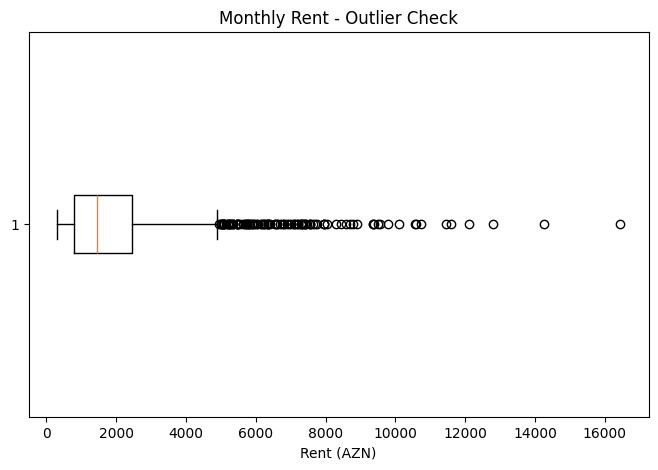

In [505]:
# Plot a boxplot for monthly rent
plt.figure(figsize=(8, 5))
plt.boxplot(rent["monthly_rent_azn"], vert=False)
plt.title("Monthly Rent - Outlier Check")
plt.xlabel("Rent (AZN)")
plt.show()

In [506]:
# Use the IQR rule to identify unusually high or low monthly rent values
q1 = rent["monthly_rent_azn"].quantile(0.25)
q3 = rent["monthly_rent_azn"].quantile(0.75)
iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

out = rent[
    (rent["monthly_rent_azn"] < low) |
    (rent["monthly_rent_azn"] > high)]
len(out)

109

In [507]:
# Preview the listings identified as rent outliers
out[["neighborhood", "monthly_rent_azn"]].head(10)

,neighborhood,monthly_rent_azn
9,28 May,9500
13,28 May,6600
15,28 May,7400
31,28 May,7350
32,28 May,6950
36,28 May,5200
40,28 May,10600
41,28 May,5050
42,28 May,8600
53,Sahil,5250


## 6. EDA

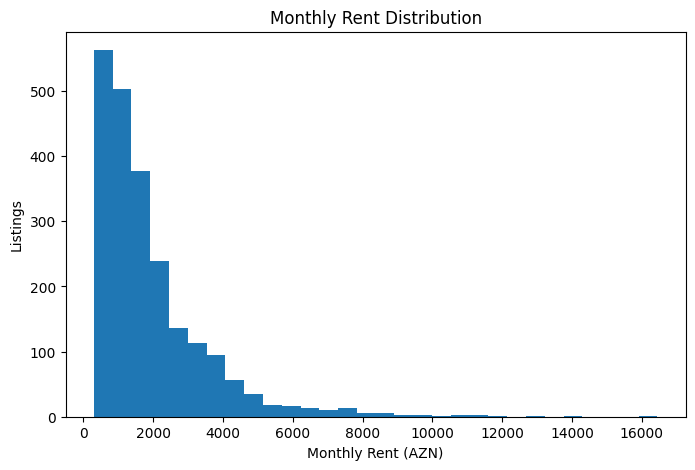

In [508]:
# Plot the distribution of monthly rent values
plt.figure(figsize=(8, 5))
plt.hist(rent["monthly_rent_azn"], bins=30)
plt.title("Monthly Rent Distribution")
plt.xlabel("Monthly Rent (AZN)")
plt.ylabel("Listings")
plt.show()

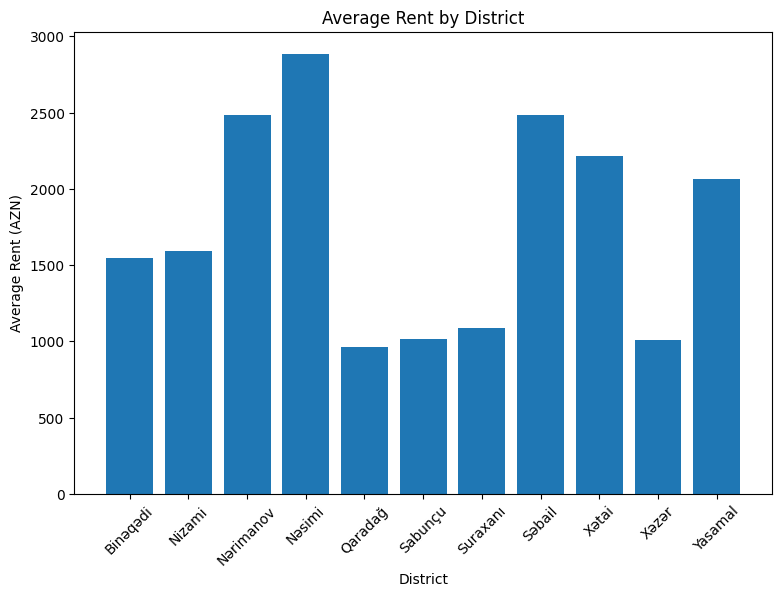

In [509]:
# Calculate average rent by district
avg_rent = rent.groupby("district")["monthly_rent_azn"].mean()
plt.figure(figsize=(9, 6))
plt.bar(avg_rent.index, avg_rent.values)
plt.title("Average Rent by District")
plt.xlabel("District")
plt.ylabel("Average Rent (AZN)")
plt.xticks(rotation=45)
plt.show()

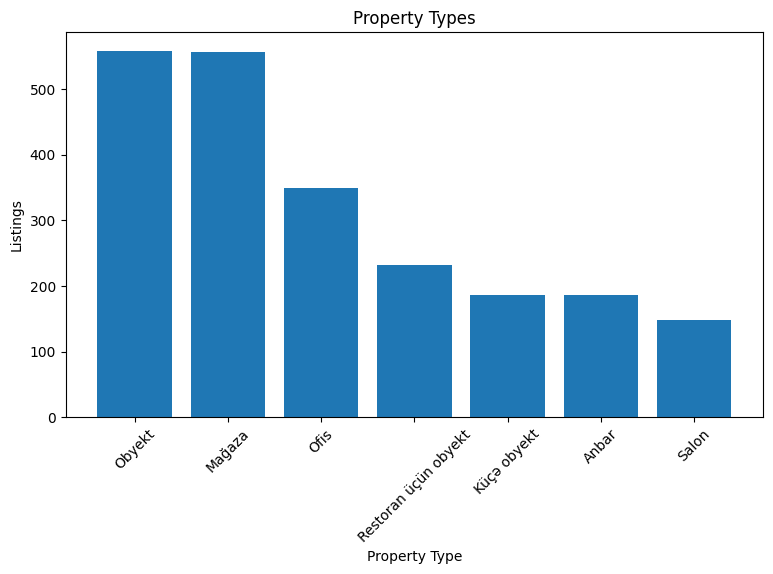

In [510]:
# Show the number of listings for each property type
types = rent["property_type"].value_counts()
plt.figure(figsize=(9, 5))
plt.bar(types.index, types.values)
plt.title("Property Types")
plt.xlabel("Property Type")
plt.ylabel("Listings")
plt.xticks(rotation=45)
plt.show()

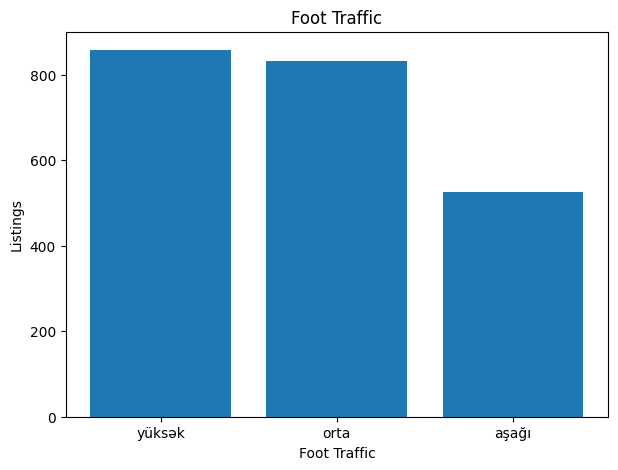

In [511]:
# Show the distribution of foot-traffic categories
traffic = rent["foot_traffic"].value_counts()
plt.figure(figsize=(7, 5))
plt.bar(traffic.index, traffic.values)
plt.title("Foot Traffic")
plt.xlabel("Foot Traffic")
plt.ylabel("Listings")
plt.show()

## 7. Metro datasının hazırlanması

In [512]:
# Preview the metro station dataset
metro.head()

,Stansiya,Station,coğrafi enliyi (latitude),coğrafi uzunluğu (longitude),yerləşdiyi ünvan,Çıxış nörmələri
0,Xocəsən,Khojasan,40421499,49778066,Dairəvi yol,Çıxış 1
1,Avtovağzal,Avtovaghzal,40421760,49796061,Bakı Sumqayıt yolu,Çıxış 1
2,Avtovağzal,Avtovaghzal,40421344,49795113,Bakı Sumqayıt yolu,Çıxış 2
3,Avtovağzal,Avtovaghzal,40420451,49795884,Bakı Sumqayıt yolu,Çıxış 3
4,Avtovağzal,Avtovaghzal,40420312,49795509,Bakı Sumqayıt yolu,Çıxış 4


In [513]:
# Rename the metro columns and convert raw coordinate values into latitude and longitude
metro.columns = [
    "station",
    "station_en",
    "lat_raw",
    "lon_raw",
    "address",
    "exit"]
metro["lat"] = pd.to_numeric(metro["lat_raw"], errors="coerce") / 1000000
metro["lon"] = pd.to_numeric(metro["lon_raw"], errors="coerce") / 1000000

In [514]:
# Check for missing metro coordinates
metro[["lat", "lon"]].isnull().sum()

,0
lat,0
lon,0


In [515]:
# Count duplicate rows in the metro dataset
metro.duplicated().sum()

np.int64(0)

## 8. OSM datasının hazırlanması

In [516]:
# Check whether OpenStreetMap point-of-interest IDs are duplicated
poi["osm_id"].duplicated().sum()

np.int64(111)

In [517]:
# Count points of interest with missing geometry
poi.geometry.isnull().sum()

np.int64(0)

In [518]:
# Remove duplicate points of interest using their OSM IDs
poi = poi.drop_duplicates(subset="osm_id")

In [519]:
# Confirm that duplicate OSM IDs have been removed
poi["osm_id"].duplicated().sum()

np.int64(0)

In [520]:
# Remove points of interest outside the Baku area
poi = poi[
    (poi.geometry.y >= 40.20) &
    (poi.geometry.y <= 40.60) &
    (poi.geometry.x >= 49.70) &
    (poi.geometry.x <= 50.10)
].copy()

In [521]:
# Inspect the main point-of-interest categories in OSM
poi["fclass"].value_counts().head(20)

,count
fclass,
convenience,2004
restaurant,1249
cafe,1190
supermarket,1070
atm,529
pharmacy,512
clothes,448
doityourself,415
car_wash,390


## 9. Ərazi datasının yaradılması

In [522]:
# Calculate average coordinates and key indicators for each district and neighbourhood
area = (
    rent.groupby(["district", "neighborhood"]).agg(
        lat=("latitude", "mean"),
        lon=("longitude", "mean"),
        listings=("listing_id", "count"),
        avg_rent=("monthly_rent_azn", "mean"),
        avg_m2=("rent_per_m2_azn", "mean"),
        parking=("parking", "mean"),
        road=("main_road", "mean"),
        foot=("foot", "mean")).reset_index()
)
area

,district,neighborhood,lat,lon,listings,avg_rent,avg_m2,parking,road,foot
0,Binəqədi,8-ci mikrorayon,40.431671,49.816375,47,1831.914894,15.200749,0.425532,0.531915,2.085106
1,Binəqədi,9-cu mikrorayon,40.436929,49.812948,43,1375.581395,14.412437,0.534884,0.627907,2.255814
2,Binəqədi,Azadlıq,40.424659,49.847823,48,1664.583333,16.221131,0.437500,0.479167,1.895833
3,Binəqədi,Biləcəri,40.447111,49.805136,41,1124.390244,11.305544,0.536585,0.536585,2.195122
4,Binəqədi,Dərnəgül,40.438353,49.841374,42,1680.952381,13.355126,0.500000,0.523810,2.166667
5,Nizami,Keşlə,40.404389,49.911473,39,1455.128205,11.124176,0.307692,0.589744,2.153846
6,Nizami,Neftçilər,40.414442,49.954794,44,1423.863636,15.314254,0.500000,0.477273,2.136364
7,Nizami,Qara Qarayev,40.411881,49.934785,43,1695.348837,14.098801,0.441860,0.581395,2.116279
8,Nizami,Xalqlar Dostluğu,40.416070,49.966128,44,1780.681818,14.320729,0.522727,0.613636,2.136364
9,Nərimanov,Atatürk prospekti,40.407754,49.856244,52,2822.115385,22.430340,0.500000,0.519231,2.134615


## 10. Əhali məlumatlarının əlavə edilməsi

In [523]:
# Add population, population density and youth-population indicators to each area
demo_index = demo.set_index("district")
area["pop"] = area["district"].map(demo_index["pop"])
area["dens"] = area["district"].map(demo_index["dens"])
area["youth"] = area["district"].map(demo_index["youth"])
area[["district", "pop", "dens", "youth"]].head()

,district,pop,dens,youth
0,Binəqədi,309.2,2378,69.4
1,Binəqədi,309.2,2378,69.4
2,Binəqədi,309.2,2378,69.4
3,Binəqədi,309.2,2378,69.4
4,Binəqədi,309.2,2378,69.4


In [524]:
# Check whether demographic indicators are missing for any areas
area[["pop", "dens", "youth"]].isnull().sum()

,0
pop,0
dens,0
youth,0


In [525]:
# Check for duplicate rows in the area dataset
area.duplicated().sum()

np.int64(0)

In [526]:
# Preview the area-level dataset
area.head()

,district,neighborhood,lat,lon,listings,avg_rent,avg_m2,parking,road,foot,pop,dens,youth
0,Binəqədi,8-ci mikrorayon,40.431671,49.816375,47,1831.914894,15.200749,0.425532,0.531915,2.085106,309.2,2378,69.4
1,Binəqədi,9-cu mikrorayon,40.436929,49.812948,43,1375.581395,14.412437,0.534884,0.627907,2.255814,309.2,2378,69.4
2,Binəqədi,Azadlıq,40.424659,49.847823,48,1664.583333,16.221131,0.437500,0.479167,1.895833,309.2,2378,69.4
3,Binəqədi,Biləcəri,40.447111,49.805136,41,1124.390244,11.305544,0.536585,0.536585,2.195122,309.2,2378,69.4
4,Binəqədi,Dərnəgül,40.438353,49.841374,42,1680.952381,13.355126,0.500000,0.523810,2.166667,309.2,2378,69.4


## 11. Ərazi göstəricilərinin hesablanması

In [527]:
# Convert area coordinates into a GeoDataFrame
g_area = gpd.GeoDataFrame(
    area.copy(),
    geometry=gpd.points_from_xy(area["lon"], area["lat"]),
    crs="EPSG:4326")
g_poi = poi.to_crs("EPSG:3857")
g_area = g_area.to_crs("EPSG:3857")
g_area["geometry"] = g_area.geometry.buffer(1000)

In [528]:
# Map OSM categories to the short names used in this project
cats = {
    "cafe": "cafe",
    "fast": "fast_food",
    "rest": "restaurant",
    "pharm": "pharmacy",
    "super": "supermarket",
    "gym": "fitness_centre",
    "beauty": "beauty_shop",
    "clothes": "clothes",
    "toy": "toy_shop",
    "book": "bookshop",
    "pet": "veterinary",
    "dentist": "dentist",
    "electronics": "computer_shop",
    "laundry": "laundry",
    "flower": "florist",
    "uni": "university",
    "school": "school",
    "hospital": "hospital",
    "clinic": "clinic",
    "office": "office",
    "bank": "bank",
    "mall": "mall"
}

for name in cats:
    g_area[name] = 0

In [529]:
# Count each OSM category within a 1 km radius of every area
for name, value in cats.items():
    p = g_poi[g_poi["fclass"] == value]
    join = gpd.sjoin(
        p[["geometry"]],
        g_area[["geometry"]],
        predicate="within",
        how="inner"
    )
    count = join.groupby("index_right").size()
    g_area.loc[count.index, name] = count

In [530]:
# Preview selected competitor and nearby-service counts for each area
g_area[[
    "district",
    "neighborhood",
    "cafe",
    "fast",
    "rest",
    "pharm",
    "super",
    "gym",
    "uni",
    "school",
    "hospital"
]].head(10)

,district,neighborhood,cafe,fast,rest,pharm,super,gym,uni,school,hospital
0,Binəqədi,8-ci mikrorayon,8,1,3,1,5,2,0,0,1
1,Binəqədi,9-cu mikrorayon,16,1,3,6,5,1,0,0,4
2,Binəqədi,Azadlıq,19,5,22,5,12,2,0,5,2
3,Binəqədi,Biləcəri,15,0,2,2,4,0,0,0,0
4,Binəqədi,Dərnəgül,6,0,8,1,5,0,0,3,3
5,Nizami,Keşlə,0,0,0,0,0,0,0,0,0
6,Nizami,Neftçilər,8,0,11,2,16,0,0,4,1
7,Nizami,Qara Qarayev,4,0,32,4,30,3,0,8,4
8,Nizami,Xalqlar Dostluğu,14,3,21,12,20,0,0,8,1
9,Nərimanov,Atatürk prospekti,11,3,11,1,8,1,2,3,6


In [531]:
# Convert the area data back to WGS84 coordinates
g_area = g_area.to_crs("EPSG:4326")
area = pd.DataFrame(g_area.drop(columns="geometry"))

In [532]:
# Calculate the distance to the nearest metro station
a = gpd.GeoDataFrame(
    area.copy(),
    geometry=gpd.points_from_xy(area["lon"], area["lat"]),
    crs="EPSG:4326")

m = gpd.GeoDataFrame(
    metro.copy(),
    geometry=gpd.points_from_xy(metro["lon"], metro["lat"]),
    crs="EPSG:4326")

a = a.to_crs("EPSG:3857")
m = m.to_crs("EPSG:3857")

near = gpd.sjoin_nearest(
    a,m[["geometry"]],distance_col="metro_dist")
area["metro_dist"] = near["metro_dist"].values

In [533]:
# Preview the area dataset after adding metro-distance information
area.head()

,district,neighborhood,lat,lon,listings,avg_rent,avg_m2,parking,road,foot,...,laundry,flower,uni,school,hospital,clinic,office,bank,mall,metro_dist
0,Binəqədi,8-ci mikrorayon,40.431671,49.816375,47,1831.914894,15.200749,0.425532,0.531915,2.085106,...,0,0,0,0,1,0,0,0,0,1359.207848
1,Binəqədi,9-cu mikrorayon,40.436929,49.812948,43,1375.581395,14.412437,0.534884,0.627907,2.255814,...,0,0,0,0,4,0,0,0,0,2204.021692
2,Binəqədi,Azadlıq,40.424659,49.847823,48,1664.583333,16.221131,0.437500,0.479167,1.895833,...,0,1,0,5,2,7,0,4,0,577.599952
3,Binəqədi,Biləcəri,40.447111,49.805136,41,1124.390244,11.305544,0.536585,0.536585,2.195122,...,0,0,0,0,0,0,0,0,0,3842.863290
4,Binəqədi,Dərnəgül,40.438353,49.841374,42,1680.952381,13.355126,0.500000,0.523810,2.166667,...,0,0,0,3,3,0,0,1,0,1820.054799


## 12. Feature Engineering

In [534]:
# Define a function to scale factors to the 0–1 range
def norm(x, reverse=False):
    lo = x.min()
    hi = x.max()
    if hi == lo:
        z = x * 0 + 0.5
    else:
        z = (x - lo) / (hi - lo)
    if reverse:
        z = 1 - z
    return z

In [535]:
# Create score columns for the main factors
area["rent_s"] = norm(area["avg_rent"], True)
area["foot_s"] = norm(area["foot"])
area["pop_s"] = norm(area["dens"])
area["youth_s"] = norm(area["youth"])

In [536]:
# Create a metro-access score and prepare parking and main-road scores
area["metro_s"] = 1 - (area["metro_dist"] / 3000)
area["metro_s"] = area["metro_s"].clip(0, 1)
area["parking_s"] = area["parking"]
area["road_s"] = area["road"]

In [537]:
# Create normalized scores for nearby facilities and competitors
competition_names = [
    "cafe", "fast", "rest", "pharm", "super", "gym", "beauty",
    "clothes", "toy", "book", "pet", "dentist", "electronics",
    "laundry", "flower"
]
for name in cats:
    area[name + "_s"] = norm(area[name], name in competition_names)

## 13. Bizneslər üçün faktor çəkiləri

In [538]:
# Define the factor weights used to evaluate each supported business type
weights = {
    "Coffee Shop": {
        "budget": 0.15, "metro": 0.15, "foot": 0.15,
        "pop": 0.10, "uni": 0.10, "office": 0.10,
        "comp": 0.15, "parking": 0.05, "road": 0.05
    },

    "Fast Food": {
        "budget": 0.10, "metro": 0.15, "foot": 0.20,
        "pop": 0.15, "uni": 0.08, "office": 0.07,
        "comp": 0.15, "parking": 0.05, "road": 0.05
    },

    "Restaurant": {
        "budget": 0.10, "metro": 0.10, "foot": 0.15,
        "pop": 0.15, "uni": 0.05, "office": 0.10,
        "comp": 0.15, "parking": 0.10, "road": 0.10
    },

    "Pharmacy": {
        "budget": 0.12, "metro": 0.08, "foot": 0.08,
        "pop": 0.20, "health": 0.20, "comp": 0.20,
        "parking": 0.02, "road": 0.05, "uni": 0.03, "office": 0.02
    },

    "Supermarket": {
        "budget": 0.12, "metro": 0.08, "foot": 0.10,
        "pop": 0.22, "comp": 0.18, "parking": 0.05,
        "road": 0.10, "shops": 0.10, "uni": 0.02, "office": 0.03
    },

    "Gym": {
        "budget": 0.12, "metro": 0.12, "foot": 0.10,
        "pop": 0.10, "youth": 0.06, "uni": 0.15,
        "office": 0.10, "comp": 0.15, "parking": 0.05, "road": 0.05
    },

    "Beauty Salon": {
        "budget": 0.15, "metro": 0.10, "foot": 0.15,
        "pop": 0.15, "office": 0.10, "comp": 0.20,
        "parking": 0.05, "road": 0.10
    },

    "Clothing Store": {
        "budget": 0.10, "metro": 0.10, "foot": 0.20,
        "pop": 0.12, "uni": 0.05, "office": 0.08,
        "comp": 0.18, "shops": 0.10, "road": 0.07
    },

    "Kids / Toy Store": {
        "budget": 0.15, "metro": 0.07, "foot": 0.08,
        "pop": 0.15, "comp": 0.20, "schools": 0.18,
        "parking": 0.08, "road": 0.09
    },

    "Bookstore": {
        "budget": 0.15, "metro": 0.12, "foot": 0.12,
        "pop": 0.10, "uni": 0.15, "office": 0.10,
        "comp": 0.15, "schools": 0.04, "road": 0.07
    },

    "Pet Shop": {
        "budget": 0.15, "metro": 0.08, "foot": 0.08,
        "pop": 0.15, "comp": 0.20, "shops": 0.10,
        "parking": 0.10, "road": 0.14
    },

    "Dental Clinic": {
        "budget": 0.12, "metro": 0.08, "foot": 0.05,
        "pop": 0.15, "comp": 0.20, "health": 0.20,
        "parking": 0.03, "road": 0.17
    },

    "Electronics Store": {
        "budget": 0.10, "metro": 0.12, "foot": 0.18,
        "pop": 0.12, "uni": 0.04, "office": 0.10,
        "comp": 0.18, "shops": 0.08, "road": 0.08
    },

    "Laundry / Dry Cleaning": {
        "budget": 0.18, "metro": 0.08, "foot": 0.07,
        "pop": 0.18, "office": 0.05, "comp": 0.18,
        "parking": 0.05, "road": 0.12, "youth": 0.09
    },

    "Flower Shop": {
        "budget": 0.15, "metro": 0.10, "foot": 0.15,
        "pop": 0.12, "uni": 0.05, "office": 0.08,
        "comp": 0.18, "shops": 0.08, "parking": 0.04,
        "road": 0.05
    }}

In [539]:
# Check that the factor weights for each business type add up to approximately 1
for biz in weights:
    print(biz, sum(weights[biz].values()))

Coffee Shop 1.0
Fast Food 1.0
Restaurant 1.0
Pharmacy 1.0
Supermarket 1.0
Gym 1.0
Beauty Salon 1.0
Clothing Store 1.0
Kids / Toy Store 1.0
Bookstore 1.0
Pet Shop 1.0
Dental Clinic 1.0
Electronics Store 1.0
Laundry / Dry Cleaning 1.0
Flower Shop 1.0


In [540]:
# Map business names to their competitor-score columns
comp_col = {
    "Coffee Shop": "cafe_s",
    "Fast Food": "fast_s",
    "Restaurant": "rest_s",
    "Pharmacy": "pharm_s",
    "Supermarket": "super_s",
    "Gym": "gym_s",
    "Beauty Salon": "beauty_s",
    "Clothing Store": "clothes_s",
    "Kids / Toy Store": "toy_s",
    "Bookstore": "book_s",
    "Pet Shop": "pet_s",
    "Dental Clinic": "dentist_s",
    "Electronics Store": "electronics_s",
    "Laundry / Dry Cleaning": "laundry_s",
    "Flower Shop": "flower_s"
}

# Map additional OSM factors used by some business types
extra_col = {
    "uni": "uni_s",
    "office": "office_s",
    "health": "hospital_s",
    "schools": "school_s",
    "shops": "mall_s"
}

# Map the columns used to display raw competitor counts
comp_count_col = {
    "Coffee Shop": "cafe",
    "Fast Food": "fast",
    "Restaurant": "rest",
    "Pharmacy": "pharm",
    "Supermarket": "super",
    "Gym": "gym",
    "Beauty Salon": "beauty",
    "Clothing Store": "clothes",
    "Kids / Toy Store": "toy",
    "Bookstore": "book",
    "Pet Shop": "pet",
    "Dental Clinic": "dentist",
    "Electronics Store": "electronics",
    "Laundry / Dry Cleaning": "laundry",
    "Flower Shop": "flower"
}

## 14. Recommendation sistemi

In [541]:
# Calculate suitability scores for the selected business
def get_score(biz, budget, priority=[], target=[]):

    d = area.copy()

    # Calculate budget fit
    rent_limit = budget * 0.10

    fit = rent.groupby("neighborhood")["monthly_rent_azn"].apply(
        lambda x: (x <= rent_limit).mean()
    )

    d["budget_fit"] = d["neighborhood"].map(fit).fillna(0)

    # Get the base factor weights for the selected business
    w = weights[biz].copy()

    # Increase the weights of the user's selected priorities
    for p in priority:
        if p in w:
           w[p] = w[p] * 1.2

    # Increase the weights of factors relevant to the selected target customers
    for t in target:
        if t in w:
            w[t] = w[t] * 1.15

    # Normalize the weights so that they sum to 1
    total = sum(w.values())

    for key in w:
        w[key] = w[key] / total

    # Calculate the final suitability score
    d["score"] = 0

    for key, value in w.items():

        if key == "budget":
            col = "budget_fit"

        elif key == "comp":
            col = comp_col[biz]

        elif key in extra_col:
            col = extra_col[key]

        else:
            col = key + "_s"

        d["score"] = d["score"] + d[col] * value

    d["score"] = d["score"] * 100

    return d.sort_values("score", ascending=False).reset_index(drop=True)

## 15. Target müştəri faktorları

In [542]:
# Define which factors are emphasized for each target customer group
target_w = {
    "Students": ["uni", "youth", "metro", "foot"],
    "Office Workers": ["office", "metro", "foot"],
    "Families": ["pop", "schools", "parking"],
    "Young People": ["youth", "foot", "metro"],
    "General": []
}

# Prepare a short explanation for each target customer group
target_text = {
    "Students": "Universitet, gənc əhali, metro və piyada axınına görə tələbələr üçün uyğundur.",
    "Office Workers": "Ofis və metro yaxınlığı, həmçinin piyada axını ofis işçiləri üçün uyğundur.",
    "Families": "Əhali, məktəb və parking göstəricilərinə görə ailələr üçün uyğundur.",
    "Young People": "Gənc əhali, metro və piyada axını gənclər üçün uyğundur.",
    "General": "Ümumi müştəri axını üçün əsas ərazi göstəricilərinə baxılır."
}

## 16. İlk test

In [543]:
# Get an initial recommendation for a coffee shop with a total budget of 20,000 AZN
res = get_score("Coffee Shop",20000)
res[[
        "district",
        "neighborhood",
        "score",
        "avg_rent",
        "budget_fit",
        "metro_dist",
        "foot",
        "dens",
        "cafe",
        "uni",
        "office",
        "parking",
        "road"]].head(10)

,district,neighborhood,score,avg_rent,budget_fit,metro_dist,foot,dens,cafe,uni,office,parking,road
0,Nəsimi,Tibb Universiteti,71.794959,3204.807692,0.269231,1225.252787,2.365385,21970,4,3,0,0.365385,0.769231
1,Nəsimi,Memar Əcəmi,64.242595,1975.531915,0.702128,564.280944,2.148936,21970,6,0,0,0.382979,0.617021
2,Nərimanov,Gənclik,63.997765,3258.490566,0.358491,155.227306,2.150943,9075,12,3,0,0.320755,0.603774
3,Nəsimi,28 May,62.248995,3366.346154,0.403846,340.801314,2.115385,21970,61,3,0,0.596154,0.557692
4,Yasamal,Yasamal,61.341862,2102.083333,0.645833,474.322249,2.229167,9735,6,0,0,0.562500,0.583333
5,Yasamal,Elmlər Akademiyası,59.449899,2867.592593,0.537037,997.368208,2.277778,9735,20,1,0,0.444444,0.648148
6,Nərimanov,Montin,58.371725,1826.086957,0.695652,568.090250,2.108696,9075,3,0,0,0.478261,0.695652
7,Nizami,Qara Qarayev,57.214867,1695.348837,0.720930,760.172674,2.116279,9310,4,0,0,0.441860,0.581395
8,Nərimanov,Atatürk prospekti,57.030124,2822.115385,0.403846,1047.342419,2.134615,9075,11,2,0,0.500000,0.519231
9,Nəsimi,Nəsimi bazarı,56.918693,2295.000000,0.580000,1509.035669,2.020000,21970,8,1,0,0.460000,0.540000


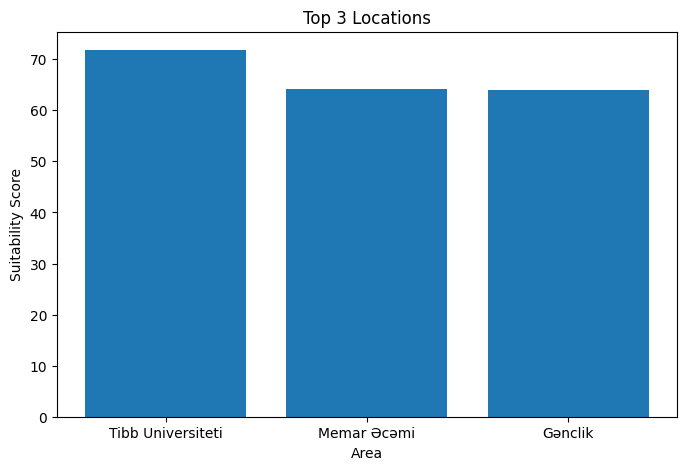

In [544]:
# Plot the top three recommended areas
top3 = res.head(3)
plt.figure(figsize=(8, 5))
plt.bar(top3["neighborhood"], top3["score"])
plt.title("Top 3 Locations")
plt.xlabel("Area")
plt.ylabel("Suitability Score")
plt.show()

## 17. Top 3 nəticənin detallı göstərilməsi

In [545]:
# Display detailed information about the top three recommended areas
top3 = res.head(3).copy()
display(
    top3[[
            "district",
            "neighborhood",
            "score",
            "avg_rent",
            "budget_fit",
            "metro_dist"
        ]])

for i, row in top3.iterrows():
    print(
        str(i + 1) + ".",
        row["neighborhood"],
        "- Score:", round(row["score"], 1),
        "- Orta kiraye:", round(row["avg_rent"]), "AZN",
        "- Büdcəyə uyğunluq:", round(row["budget_fit"] * 100), "%",
        "- Metro:", round(row["metro_dist"]), "m"
    )

,district,neighborhood,score,avg_rent,budget_fit,metro_dist
0,Nəsimi,Tibb Universiteti,71.794959,3204.807692,0.269231,1225.252787
1,Nəsimi,Memar Əcəmi,64.242595,1975.531915,0.702128,564.280944
2,Nərimanov,Gənclik,63.997765,3258.490566,0.358491,155.227306


1. Tibb Universiteti - Score: 71.8 - Orta kiraye: 3205 AZN - Büdcəyə uyğunluq: 27 % - Metro: 1225 m
2. Memar Əcəmi - Score: 64.2 - Orta kiraye: 1976 AZN - Büdcəyə uyğunluq: 70 % - Metro: 564 m
3. Gənclik - Score: 64.0 - Orta kiraye: 3258 AZN - Büdcəyə uyğunluq: 36 % - Metro: 155 m


## 18. Bu ərazi kim üçün uyğundur?

In [546]:
# Show a short explanation for the selected target customer group
selected_target = ["Students"]
for target in selected_target:
    print(target + ":", target_text[target])

Students: Universitet, gənc əhali, metro və piyada axınına görə tələbələr üçün uyğundur.


In [547]:
# Show the main advantages of the selected area
print("Area:", row["neighborhood"])
print("Score:", round(row["score"], 1))
print("Average rent:", round(row["avg_rent"], 0), "AZN")
print("Distance to metro:", round(row["metro_dist"]), "m")

Area: Gənclik
Score: 64.0
Average rent: 3258.0 AZN
Distance to metro: 155 m


## 19. Machine Learning — K-Means

In [548]:
# Select features for grouping areas with similar characteristics
km_cols = [
    "dens",
    "avg_rent",
    "metro_dist",
    "foot",
    "parking",
    "road"
]
km_data = area[km_cols].copy()
for col in km_cols:
    km_data[col] = norm(
        km_data[col],
        col in ["avg_rent", "metro_dist"])

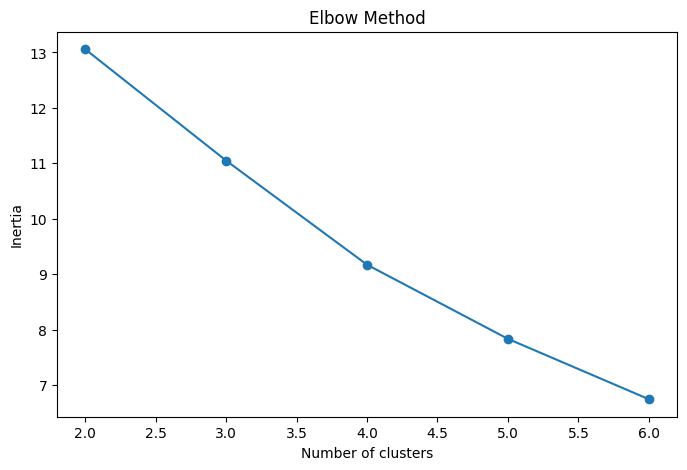

In [549]:
# Use the Elbow Method to help choose the number of clusters
errors = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(km_data)
    errors.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 7), errors, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [550]:
# Fit a three-cluster K-Means model and assign a cluster to each area
km = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10)
area["cluster"] = km.fit_predict(km_data)

In [551]:
# Show the average indicators for each cluster
cluster_info = (area.groupby("cluster")[["dens", "avg_rent", "metro_dist", "foot", "parking", "road"]].mean().round(1))
cluster_info

,dens,avg_rent,metro_dist,foot,parking,road
cluster,,,,,,
0,21970.0,2867.5,776.9,2.1,0.5,0.6
1,1425.5,1078.7,11711.7,2.2,0.5,0.6
2,7550.6,2115.8,1226.0,2.1,0.4,0.6


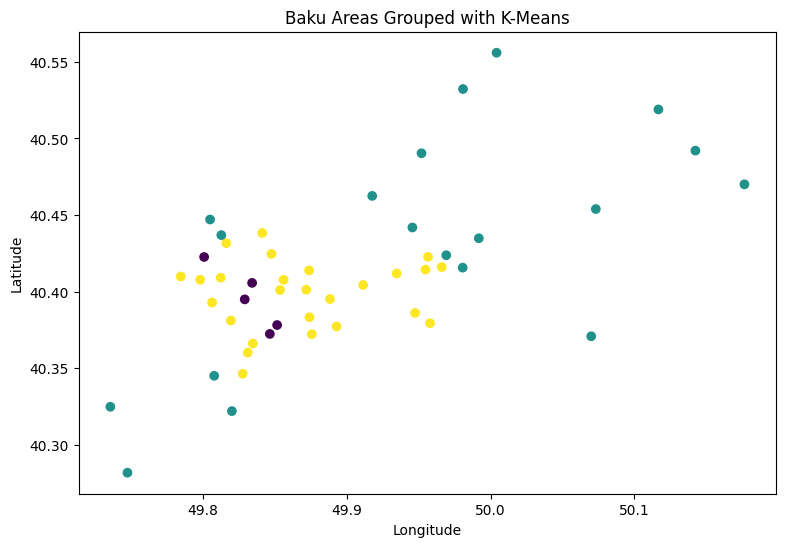

In [552]:
# Plot the areas and color them by cluster
plt.figure(figsize=(9, 6))
plt.scatter(
    area["lon"],
    area["lat"],
    c=area["cluster"]
)
plt.title("Baku Areas Grouped with K-Means")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

## 20. Machine Learning — Random Forest vs LinearRegression


In [553]:
# Import the models, data-splitting function and evaluation metrics used for rent prediction
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [554]:
# Choose the input features that may help predict monthly rent
features = [
    "area_m2",
    "metro_distance_m",
    "main_road",
    "parking",
    "pop",
    "dens",
    "youth",
    "latitude",
    "longitude"
]

In [555]:
# Separate the predictor columns (X) from the monthly-rent target (y)
X = rent[features]
y = rent["monthly_rent_azn"]

In [556]:
# Split the data into training and testing sets, keeping 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2,random_state=42)

In [557]:
# Train a Linear Regression model and compare its performance on training and test data
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_train_pred = linear_model.predict(X_train)
y_test_pred = linear_model.predict(X_test)
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Train R²:", train_r2)
print("Test R²:", test_r2)

Train R²: 0.7055613556893434
Test R²: 0.6403586957419232


In [558]:
# Create and train the Random Forest model
model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=5,
    random_state=42
)

model.fit(X_train, y_train)

train_score = model.score(X_train, y_train)
test_score = model.score(X_test, y_test)

print("Train Score:",train_score)
print("Test Score:", test_score)

Train Score: 0.94602604783366
Test Score: 0.8521670575398554


In [559]:
# Rank the input features by their importance in the Random Forest model
importance = pd.DataFrame({
    "feature": features,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)
importance

,feature,importance
0,area_m2,0.667597
5,dens,0.156531
8,longitude,0.112082
7,latitude,0.049459
1,metro_distance_m,0.009006
3,parking,0.001596
2,main_road,0.001404
6,youth,0.001249
4,pop,0.001077


## 28. Biznes ve Budce Parametrleri

In [560]:
# Create a dropdown for selecting the business type
biz_box = widgets.Dropdown(
    options=list(weights.keys()),
    value="Coffee Shop",
    description="Business:"
)
# Create a slider for selecting the total business budget
budget_box = widgets.IntSlider(
    value=20000,
    min=1000,
    max=50000,
    step=1000,
    description="Budget:"
)
# Create checkboxes for selecting target customer groups
students_box = widgets.Checkbox(False, description="Students")
office_target_box = widgets.Checkbox(False, description="Office Workers")
families_box = widgets.Checkbox(False, description="Families")
young_box = widgets.Checkbox(False, description="Young People")
general_box = widgets.Checkbox(True, description="General")

In [561]:
# Create checkboxes for the location factors the user wants to prioritize
metro_box = widgets.Checkbox(False, description="Metro")
rent_box = widgets.Checkbox(False, description="Low Rent")
comp_box = widgets.Checkbox(False, description="Low Competition")
foot_box = widgets.Checkbox(False, description="Foot Traffic")
uni_box = widgets.Checkbox(False, description="University")
office_box = widgets.Checkbox(False, description="Office")
parking_box = widgets.Checkbox(False, description="Parking")

btn = widgets.Button(description="Find Location")
out = widgets.Output()

In [562]:
# Read the selected controls, calculate recommendations and display the results
def show_result(b):

    global res

    with out:
        out.clear_output()

        priority = []

        if metro_box.value:
            priority.append("metro")

        if rent_box.value:
            priority.append("budget")

        if comp_box.value:
            priority.append("comp")

        if foot_box.value:
            priority.append("foot")

        if uni_box.value:
            priority.append("uni")

        if office_box.value:
            priority.append("office")

        if parking_box.value:
            priority.append("parking")

        target = []

        if students_box.value:
            target.extend(target_w["Students"])

        if office_target_box.value:
            target.extend(target_w["Office Workers"])

        if families_box.value:
            target.extend(target_w["Families"])

        if young_box.value:
            target.extend(target_w["Young People"])

        if general_box.value:
            target.extend(target_w["General"])

        target = list(dict.fromkeys(target))

        result = get_score(
            biz_box.value,
            budget_box.value,
            priority,
            target
        )

        res = result.copy()

        best = result.iloc[0]

        print()
        print("==========================================")
        print("              RECOMMENDATION")
        print("==========================================")
        print()

        print("Biznes:", biz_box.value)
        print("Büdcə:", budget_box.value, "AZN")

        if priority:
            print("Prioritetlər:", ", ".join(priority))
        else:
            print("Prioritetlər: Yoxdur")

        if target:
            print("Hədəf müştəri:", ", ".join(target))
        else:
            print("Hədəf müştəri: Yoxdur")

        print()
        print("------------------------------------------")
        print("TÖVSİYƏ OLUNAN ƏRAZİ")
        print("------------------------------------------")
        print()

        print("Area:", best["neighborhood"])
        print("Suitability Score:", round(best["score"], 1), "%")

        print()
        print("------------------------------------------")
        print("ƏRAZİ HAQQINDA")
        print("------------------------------------------")

        print("Average rent:", round(best["avg_rent"], 0), "AZN")
        print("Büdcə uyğunluğu:", round(best["budget_fit"] * 100, 1), "%")
        print("Distance to metro:", round(best["metro_dist"], 0), "m")
        print("Piyada axını:", round(best["foot"], 1))
        print("Əhali sıxlığı:", round(best["dens"], 0))

        print()
        print("------------------------------------------")
        print("BU ƏRAZİ NİYƏ TÖVSİYƏ OLUNUR?")
        print("------------------------------------------")

        if best["budget_fit"] >= result["budget_fit"].median():
            print("✓ Büdcəyə uyğun icarə imkanları var.")

        if best["metro_dist"] <= result["metro_dist"].median():
            print("✓ Metroya məsafəsi əlverişlidir.")

        if best["foot"] >= result["foot"].median():
            print("✓ Piyada axını yaxşıdır.")

        if best["dens"] >= result["dens"].median():
            print("✓ Əhali sıxlığı yaxşıdır.")

        print()
        print("------------------------------------------")
        print("ÜSTÜN TƏRƏFLƏR")
        print("------------------------------------------")

        if best["budget_fit"] >= result["budget_fit"].median():
            print("✓ Büdcə uyğunluğu yaxşıdır.")

        if best["metro_dist"] <= result["metro_dist"].median():
            print("✓ Metro əlçatanlığı yaxşıdır.")

        if best["foot"] >= result["foot"].median():
            print("✓ Piyada axını yaxşıdır.")

        if best["dens"] >= result["dens"].median():
            print("✓ Əhali sıxlığı yüksəkdir.")

        print()
        print("------------------------------------------")
        print("ZƏİF TƏRƏFLƏR")
        print("------------------------------------------")

        if best["budget_fit"] < result["budget_fit"].median():
            print("× Büdcə uyğunluğu nisbətən aşağıdır.")

        if best["metro_dist"] > result["metro_dist"].median():
            print("× Metro məsafəsi nisbətən çoxdur.")

        if best["foot"] < result["foot"].median():
            print("× Piyada axını nisbətən aşağıdır.")

        if best["dens"] < result["dens"].median():
            print("× Əhali sıxlığı nisbətən aşağıdır.")

        print()
        print("==========================================")
        print("          TOP 5 ALTERNATİV ƏRAZİ")
        print("==========================================")

        display(
            result.head(5)[
                [
                    "district",
                    "neighborhood",
                    "score",
                    "avg_rent",
                    "budget_fit",
                    "metro_dist"
                ]
            ]
        )

        print()
        print("------------------------------------------")
        print("NƏTİCƏ")
        print("------------------------------------------")

        print(
            biz_box.value,
            "üçün",
            best["neighborhood"],
            "ərazisi",
            round(best["score"], 1),
            "% uyğunluq ilə tövsiyə olunur."
        )

In [563]:
# Display the recommendation results when the button is clicked
btn._click_handlers.callbacks = []
btn.on_click(show_result)

display(
    biz_box,
    budget_box,
    widgets,
    students_box,
    office_target_box,
    families_box,
    young_box,
    general_box,
    metro_box,
    rent_box,
    comp_box,
    foot_box,
    uni_box,
    office_box,
    parking_box,
    btn,
    out
)

Dropdown(description='Business:', options=('Coffee Shop', 'Fast Food', 'Restaurant', 'Pharmacy', 'Supermarket'…

IntSlider(value=20000, description='Budget:', max=50000, min=1000, step=1000)

<module 'ipywidgets' from '/usr/local/lib/python3.13/dist-packages/ipywidgets/__init__.py'>

Checkbox(value=False, description='Students')

Checkbox(value=False, description='Office Workers')

...

Checkbox(value=False, description='University')

Checkbox(value=False, description='Office')

Checkbox(value=False, description='Parking')

Button(description='Find Location', style=ButtonStyle())

Output()

In [565]:
# Create an interactive map showing the five highest-ranked areas with colored markers and labels
def draw_map():
    top5 = res.head(5).copy()

    m = folium.Map(location=[40.405, 49.87], zoom_start=11, tiles=None)

    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        attr="Esri, HERE, Garmin, © OpenStreetMap contributors",
        name="Street Map"
    ).add_to(m)

    colors = ["red", "orange", "green", "blue", "purple"]

    for i, (_, row) in enumerate(top5.iterrows(), 1):

        name = str(row["neighborhood"])
        score = round(row["score"], 1)

        # Add a colored map marker.
        folium.Marker(
            location=[row["lat"], row["lon"]],
            tooltip=name + " | Score: " + str(score) + "%",
            icon=folium.Icon(color=colors[i - 1], icon="map-marker", prefix="fa")
        ).add_to(m)

        # Add a label with the area's name and ranking beside the marker.
        label_html = """
        <div style="
            font-size: 11px;
            font-weight: bold;
            color: #222;
            background: white;
            padding: 2px 5px;
            border-radius: 3px;
            border: 1px solid #aaa;
            white-space: nowrap;
            box-shadow: 1px 1px 2px rgba(0,0,0,0.2);
        ">
            """ + str(i) + ". " + name + """
        </div>
        """

        folium.Marker(
            location=[row["lat"], row["lon"]],
            icon=folium.DivIcon(
                html=label_html,
                icon_size=(120, 25),
                icon_anchor=(-5, 10)
            )
        ).add_to(m)

    locations = [[row["lat"], row["lon"]] for _, row in top5.iterrows()]
    m.fit_bounds(locations)

    return m
draw_map()